# A7v2. 5G NR tasodifiy ulanish: PRACH occupancy, 3GPP BI backoff va retransmission

**Python + Google Colab**  
**Davomiyligi:** 2 soat  
**VARIANT = 1..15**

Model 4-step CBRA protsedurasining **Msg1/preamble-resolution** qismini modellashtiradi. Singleton preamble to‘liq Msg1–Msg4 success bilan tenglashtirilmaydi. Static BI 3GPP TS 38.321 Backoff Parameter jadvalidan foydalanadi; Load-Adaptive BI esa idle-preamble kuzatuvidan $\hat G=-\ln(\hat P_0)$ ni baholab, aynan shu standart BI jadvalidan kattaroq qiymat tanlaydigan pedagogik controllerdir.

## 1. Model funksiyalari va 3GPP parametr jadvallari

In [1]:
import matplotlib.pyplot as plt
import math
import numpy as np
import pandas as pd

POLICIES = ('Static BI', 'Load-Adaptive BI')

# 3GPP TS 38.321 Table 7.2-1 Backoff Parameter values (non-reserved entries), ms.
BACKOFF_PARAMETER_MS = (5, 10, 20, 30, 40, 60, 80, 120, 160, 240, 320, 480, 960, 1920)
# 3GPP TS 38.331 preambleTransMax enumeration values.
PREAMBLE_TRANS_MAX_VALUES = (3, 4, 5, 6, 7, 8, 10, 20, 50, 100, 200)

# Fifteen reproducible teaching scenarios. All BI and preambleTransMax values are standard-table values.
VARIANTS = [
    dict(variant=1,  n_devices=180, n_preambles=48, rao_period_ms=5.0,  bi_ms=20,  preamble_trans_max=8,  access_target_ms=100.0, seed=701),
    dict(variant=2,  n_devices=120, n_preambles=36, rao_period_ms=5.0,  bi_ms=20,  preamble_trans_max=7,  access_target_ms=100.0, seed=702),
    dict(variant=3,  n_devices=240, n_preambles=54, rao_period_ms=5.0,  bi_ms=30,  preamble_trans_max=8,  access_target_ms=100.0, seed=703),
    dict(variant=4,  n_devices=90,  n_preambles=24, rao_period_ms=10.0, bi_ms=40,  preamble_trans_max=6,  access_target_ms=150.0, seed=704),
    dict(variant=5,  n_devices=300, n_preambles=48, rao_period_ms=5.0,  bi_ms=40,  preamble_trans_max=10, access_target_ms=120.0, seed=705),
    dict(variant=6,  n_devices=160, n_preambles=32, rao_period_ms=5.0,  bi_ms=30,  preamble_trans_max=8,  access_target_ms=100.0, seed=706),
    dict(variant=7,  n_devices=220, n_preambles=40, rao_period_ms=10.0, bi_ms=40,  preamble_trans_max=8,  access_target_ms=150.0, seed=707),
    dict(variant=8,  n_devices=70,  n_preambles=54, rao_period_ms=5.0,  bi_ms=10,  preamble_trans_max=6,  access_target_ms=80.0,  seed=708),
    dict(variant=9,  n_devices=360, n_preambles=54, rao_period_ms=5.0,  bi_ms=60,  preamble_trans_max=10, access_target_ms=150.0, seed=709),
    dict(variant=10, n_devices=200, n_preambles=30, rao_period_ms=5.0,  bi_ms=40,  preamble_trans_max=8,  access_target_ms=120.0, seed=710),
    dict(variant=11, n_devices=140, n_preambles=44, rao_period_ms=10.0, bi_ms=30,  preamble_trans_max=7,  access_target_ms=150.0, seed=711),
    dict(variant=12, n_devices=280, n_preambles=36, rao_period_ms=5.0,  bi_ms=60,  preamble_trans_max=10, access_target_ms=150.0, seed=712),
    dict(variant=13, n_devices=110, n_preambles=28, rao_period_ms=5.0,  bi_ms=20,  preamble_trans_max=7,  access_target_ms=100.0, seed=713),
    dict(variant=14, n_devices=260, n_preambles=50, rao_period_ms=10.0, bi_ms=60,  preamble_trans_max=10, access_target_ms=180.0, seed=714),
    dict(variant=15, n_devices=320, n_preambles=40, rao_period_ms=5.0,  bi_ms=80,  preamble_trans_max=10, access_target_ms=180.0, seed=715),
]


def standard_bi_ms(value):
    value = int(value)
    if value not in BACKOFF_PARAMETER_MS:
        raise ValueError(f'BI must be one of 3GPP table values: {BACKOFF_PARAMETER_MS}')
    return value


def validate_variant(v):
    n = int(v['n_devices']); m = int(v['n_preambles'])
    period = float(v['rao_period_ms'])
    bi = int(v['bi_ms']); amax = int(v['preamble_trans_max'])
    target = float(v.get('access_target_ms', 100.0))
    if n <= 0 or not (1 <= m <= 64) or period <= 0 or target < 0:
        raise ValueError('invalid random-access scenario')
    standard_bi_ms(bi)
    if amax not in PREAMBLE_TRANS_MAX_VALUES:
        raise ValueError(f'preamble_trans_max must be one of {PREAMBLE_TRANS_MAX_VALUES}')
    return True


def theoretical_first_rao(n_devices: int, n_preambles: int):
    n = int(n_devices); m = int(n_preambles)
    if n < 0 or m <= 0:
        raise ValueError('n_devices must be >=0 and n_preambles >0')
    if n == 0:
        p_single_ue = 1.0
        p0 = 1.0
        p1_preamble = 0.0
    elif n == 1:
        p_single_ue = 1.0
        p0 = (1.0 - 1.0/m)
        p1_preamble = 1.0/m
    else:
        p_single_ue = (1.0 - 1.0/m) ** (n-1)
        p0 = (1.0 - 1.0/m) ** n
        p1_preamble = (n/m) * (1.0 - 1.0/m) ** (n-1)
    expected_singletons = n * p_single_ue
    expected_idle = m * p0
    expected_collision_preambles = m * max(1.0 - p0 - p1_preamble, 0.0)
    G = n/m if m else 0.0
    poisson_singleton = G * math.exp(-G) if G >= 0 else 0.0
    return {
        'n_devices': n,
        'n_preambles': m,
        'offered_load_G': float(G),
        'per_ue_singleton_probability': float(p_single_ue),
        'expected_singletons': float(expected_singletons),
        'expected_idle_preambles': float(expected_idle),
        'expected_collision_preambles': float(expected_collision_preambles),
        'expected_used_preambles': float(m - expected_idle),
        'expected_ue_collision_fraction': float(0.0 if n == 0 else 1.0 - p_single_ue),
        'poisson_idle_probability': float(math.exp(-G)),
        'poisson_singleton_per_preamble': float(poisson_singleton),
        'poisson_expected_singletons': float(m * poisson_singleton),
        'poisson_optimal_G': 1.0,
        'poisson_max_singletons': float(m / math.e),
    }


def _snap_bi_up(target_ms: float):
    target = max(float(target_ms), BACKOFF_PARAMETER_MS[0])
    for x in BACKOFF_PARAMETER_MS:
        if x >= target - 1e-12:
            return int(x)
    return int(BACKOFF_PARAMETER_MS[-1])


def estimate_load_from_idle(idle_preambles: int, n_preambles: int):
    """Poisson occupancy estimate G_hat=-ln(P0), using Jeffreys-like 0.5 smoothing."""
    m = int(n_preambles); idle = int(idle_preambles)
    if m <= 0 or not (0 <= idle <= m):
        raise ValueError('invalid idle-preamble observation')
    p0_hat = (idle + 0.5) / (m + 1.0)
    return float(max(-math.log(max(p0_hat, 1e-12)), 0.0))


def adaptive_bi_ms(base_bi_ms: int, idle_preambles: int, n_preambles: int):
    """Teaching controller using an observable idle-preamble load estimate; output is a standard BI value."""
    base = standard_bi_ms(base_bi_ms)
    ghat = estimate_load_from_idle(idle_preambles, n_preambles)
    # Keep base BI at/under light load, then increase smoothly with estimated overload.
    multiplier = 1.0 + 0.75 * max(ghat - 1.0, 0.0)
    return _snap_bi_up(base * multiplier)


def _percentile(values, p):
    arr = np.asarray(values, float)
    return 0.0 if arr.size == 0 else float(np.percentile(arr, p))


def _sample_ci95(values):
    arr = np.asarray(values, float)
    if arr.size <= 1:
        return 0.0
    return float(1.96 * np.std(arr, ddof=1) / math.sqrt(arr.size))


def simulate_random_access(v: dict, policy: str, max_raos: int = 2000):
    if policy not in POLICIES:
        raise ValueError(f'policy must be one of {POLICIES}')
    v = dict(v); validate_variant(v)
    n = int(v['n_devices']); m = int(v['n_preambles'])
    period = float(v['rao_period_ms']); base_bi = int(v['bi_ms'])
    amax = int(v['preamble_trans_max']); target_ms = float(v.get('access_target_ms', 100.0))
    rng = np.random.default_rng(int(v['seed']))

    next_rao = np.zeros(n, dtype=int)
    attempts = np.zeros(n, dtype=int)
    resolved = np.zeros(n, dtype=bool)
    success_rao = np.full(n, -1, dtype=int)
    last_bi_ms = base_bi

    trace = []
    total_tx = 0
    collided_tx = 0
    total_collision_preambles = 0
    total_singletons = 0
    total_idle_active = 0
    active_raos = 0

    for rao in range(int(max_raos)):
        contenders = np.where((~resolved) & (next_rao <= rao))[0]
        if contenders.size == 0:
            if resolved.all():
                break
            trace.append({
                'rao': rao, 'time_ms': rao*period, 'contenders': 0,
                'resolved_singletons': 0, 'collided_devices': 0,
                'idle_preambles': m, 'singleton_preambles': 0, 'collision_preambles': 0,
                'ue_collision_tx_fraction': 0.0, 'used_preamble_collision_fraction': 0.0,
                'estimated_load_G': 0.0, 'bi_ms': int(last_bi_ms),
                'remaining_devices': int((~resolved).sum()),
            })
            continue

        active_raos += 1
        choices = rng.integers(0, m, size=contenders.size)
        counts = np.bincount(choices, minlength=m)
        singleton_preambles = np.where(counts == 1)[0]
        collision_preambles = np.where(counts >= 2)[0]
        singleton_mask = np.isin(choices, singleton_preambles)
        success_ids = contenders[singleton_mask]
        collision_ids = contenders[~singleton_mask]

        attempts[contenders] += 1
        total_tx += int(contenders.size)
        collided_tx += int(collision_ids.size)
        total_collision_preambles += int(collision_preambles.size)
        total_singletons += int(singleton_preambles.size)
        idle = int((counts == 0).sum())
        total_idle_active += idle

        if success_ids.size:
            resolved[success_ids] = True
            success_rao[success_ids] = rao

        if policy == 'Static BI':
            bi_ms = base_bi
            ghat = estimate_load_from_idle(idle, m)
        else:
            ghat = estimate_load_from_idle(idle, m)
            bi_ms = adaptive_bi_ms(base_bi, idle, m)
        last_bi_ms = bi_ms

        if collision_ids.size:
            for uid in collision_ids:
                if attempts[uid] >= amax:
                    resolved[uid] = True  # unresolved by Msg1 after max preamble transmissions -> failure
                else:
                    backoff_ms = int(rng.integers(0, bi_ms + 1)) if bi_ms > 0 else 0
                    wait_raos = int(math.ceil(backoff_ms / period)) if backoff_ms > 0 else 0
                    next_rao[uid] = rao + 1 + wait_raos

        used = int(singleton_preambles.size + collision_preambles.size)
        trace.append({
            'rao': rao, 'time_ms': rao*period, 'contenders': int(contenders.size),
            'resolved_singletons': int(success_ids.size), 'collided_devices': int(collision_ids.size),
            'idle_preambles': idle, 'singleton_preambles': int(singleton_preambles.size),
            'collision_preambles': int(collision_preambles.size),
            'ue_collision_tx_fraction': float(collision_ids.size/contenders.size if contenders.size else 0.0),
            'used_preamble_collision_fraction': float(collision_preambles.size/used if used else 0.0),
            'estimated_load_G': float(ghat), 'bi_ms': int(bi_ms),
            'remaining_devices': int((~resolved).sum()),
        })
        if resolved.all():
            break
    else:
        # Horizon-censoring is counted as failure; normally not reached for teaching scenarios.
        resolved[~resolved] = True

    success = success_rao >= 0
    resolved_devices = int(success.sum())
    failed_devices = int(n - resolved_devices)
    waits = (success_rao[success] * period).astype(float) if resolved_devices else np.array([], float)
    spans = ((success_rao[success] + 1) * period).astype(float) if resolved_devices else np.array([], float)
    within_target = int(np.sum(success & ((success_rao * period) <= target_ms)))
    used_raos = (trace[-1]['rao'] + 1) if trace else 0
    used_preambles = total_singletons + total_collision_preambles

    kpi = {
        'n_devices': n, 'n_preambles': m, 'offered_load_G': n/m,
        'rao_period_ms': period, 'base_bi_ms': base_bi, 'preamble_trans_max': amax,
        'access_target_ms': target_ms,
        'resolved_devices': resolved_devices, 'failed_devices': failed_devices,
        'resolution_rate': resolved_devices/n, 'failure_rate': failed_devices/n,
        'resolved_within_target_rate': within_target/n,
        'total_preamble_transmissions': int(total_tx),
        'total_retransmissions': int(max(total_tx - n, 0)),
        'ue_collision_tx_fraction': float(collided_tx/total_tx if total_tx else 0.0),
        'collision_preamble_fraction_used': float(total_collision_preambles/used_preambles if used_preambles else 0.0),
        'idle_preamble_fraction_active': float(total_idle_active/(active_raos*m) if active_raos and m else 0.0),
        'mean_attempts_per_device': float(attempts.mean()),
        'mean_attempts_resolved': float(attempts[success].mean()) if resolved_devices else 0.0,
        'mean_contention_wait_ms': float(waits.mean()) if resolved_devices else 0.0,
        'p95_contention_wait_ms': _percentile(waits, 95),
        'p99_contention_wait_ms': _percentile(waits, 99),
        'mean_observation_span_ms': float(spans.mean()) if resolved_devices else 0.0,
        'active_raos': int(active_raos), 'calendar_raos_used': int(used_raos),
        'completion_span_ms': float(used_raos*period),
        'active_preamble_efficiency': float(resolved_devices/(active_raos*m) if active_raos and m else 0.0),
        'calendar_preamble_efficiency': float(resolved_devices/(used_raos*m) if used_raos and m else 0.0),
    }
    device_df = pd.DataFrame({
        'device_id': np.arange(1, n+1),
        'resolved': success,
        'attempts': attempts,
        'success_rao': success_rao,
        'contention_wait_ms': np.where(success, success_rao*period, np.nan),
        'observation_span_ms': np.where(success, (success_rao+1)*period, np.nan),
        'resolved_within_target': success & ((success_rao*period) <= target_ms),
    })
    return {'variant': v, 'policy': policy, 'kpi': kpi, 'device_results': device_df, 'rao_trace': pd.DataFrame(trace)}


MC_METRICS = (
    'resolution_rate', 'resolved_within_target_rate', 'ue_collision_tx_fraction',
    'collision_preamble_fraction_used', 'idle_preamble_fraction_active',
    'mean_attempts_per_device', 'p95_contention_wait_ms', 'p99_contention_wait_ms',
    'calendar_preamble_efficiency',
)


def monte_carlo_compare(v: dict, n_runs: int = 10, seed_offsets=None):
    if seed_offsets is None:
        seed_offsets = tuple(range(int(n_runs)))
    else:
        seed_offsets = tuple(seed_offsets)
        n_runs = len(seed_offsets)
    raw_rows = []
    for offset in seed_offsets:
        for policy in POLICIES:
            vv = dict(v); vv['seed'] = int(v['seed']) + int(offset)
            out = simulate_random_access(vv, policy)
            raw_rows.append({'run': int(offset), 'seed': vv['seed'], 'policy': policy, **out['kpi']})
    raw = pd.DataFrame(raw_rows)
    rows = []
    for policy in POLICIES:
        g = raw[raw.policy == policy]
        row = {'policy': policy, 'n_runs': int(len(g))}
        for metric in MC_METRICS:
            vals = g[metric].to_numpy(float)
            row[f'{metric}_mean'] = float(vals.mean())
            row[f'{metric}_ci95'] = _sample_ci95(vals)
        rows.append(row)
    return pd.DataFrame(rows), raw


def _mc_sensitivity(v, points, point_name, mutate_fn, n_runs=10, seed_offsets=None):
    rows = []
    for point in points:
        vv = dict(v); mutate_fn(vv, point)
        summary, _ = monte_carlo_compare(vv, n_runs=n_runs, seed_offsets=seed_offsets)
        summary.insert(0, point_name, point)
        rows.append(summary)
    return pd.concat(rows, ignore_index=True)


def load_sweep_mc(v, multipliers=(0.5,1.0,1.5,2.0), n_runs=10, seed_offsets=None):
    return _mc_sensitivity(
        v, multipliers, 'load_multiplier',
        lambda vv, mult: vv.update(n_devices=max(1, int(round(v['n_devices']*float(mult))))),
        n_runs=n_runs, seed_offsets=seed_offsets,
    )


def preamble_sensitivity_mc(v, preamble_counts=(24,36,48,64), n_runs=10, seed_offsets=None):
    return _mc_sensitivity(
        v, preamble_counts, 'n_preambles',
        lambda vv, m: vv.update(n_preambles=int(m)),
        n_runs=n_runs, seed_offsets=seed_offsets,
    )


def bi_sensitivity_mc(v, bi_values=(10,20,40,80,160), n_runs=10, seed_offsets=None):
    vals = tuple(standard_bi_ms(x) for x in bi_values)
    return _mc_sensitivity(
        v, vals, 'base_bi_ms',
        lambda vv, bi: vv.update(bi_ms=int(bi)),
        n_runs=n_runs, seed_offsets=seed_offsets,
    )


def variants_dataframe():
    rows=[]
    for v in VARIANTS:
        th=theoretical_first_rao(v['n_devices'],v['n_preambles'])
        rows.append({**v,'N_over_M':th['offered_load_G'],'first_rao_expected_singletons':th['expected_singletons']})
    return pd.DataFrame(rows)


def qa_all_variants(n_runs=3):
    rows=[]
    for v in VARIANTS:
        try:
            th=theoretical_first_rao(v['n_devices'],v['n_preambles'])
            summary, raw=monte_carlo_compare(v,n_runs=n_runs,seed_offsets=tuple(range(n_runs)))
            ok=True
            for _,r in summary.iterrows():
                ok &= (0 <= r['resolution_rate_mean'] <= 1)
                ok &= (0 <= r['ue_collision_tx_fraction_mean'] <= 1)
                ok &= (0 <= r['resolved_within_target_rate_mean'] <= r['resolution_rate_mean']+1e-12)
            rows.append({'variant':v['variant'],'N':v['n_devices'],'M':v['n_preambles'],'G':th['offered_load_G'],'ok':bool(ok)})
        except Exception as e:
            rows.append({'variant':v['variant'],'N':v['n_devices'],'M':v['n_preambles'],'G':np.nan,'ok':False,'error':str(e)})
    return pd.DataFrame(rows)


## 2. Variant, birinchi RAO occupancy nazariyasi va single-run natijasi

In [2]:
VARIANT=1
v=dict(VARIANTS[VARIANT-1])
th=theoretical_first_rao(v['n_devices'],v['n_preambles'])
print('Birinchi RAO nazariyasi:')
display(pd.DataFrame([th]).round(5))
comparison_rows=[]; outputs={}
for pol in POLICIES:
    o=simulate_random_access(v,pol); outputs[pol]=o
    comparison_rows.append({'policy':pol,**o['kpi']})
comparison_df=pd.DataFrame(comparison_rows)
print('Single-run KPI:')
display(comparison_df[['policy','resolution_rate','resolved_within_target_rate','ue_collision_tx_fraction','collision_preamble_fraction_used','idle_preamble_fraction_active','mean_attempts_per_device','p95_contention_wait_ms','p99_contention_wait_ms','completion_span_ms']].round(4))

Birinchi RAO nazariyasi:


,n_devices,n_preambles,offered_load_G,per_ue_singleton_probability,expected_singletons,expected_idle_preambles,expected_collision_preambles,expected_used_preambles,expected_ue_collision_fraction,poisson_idle_probability,poisson_singleton_per_preamble,poisson_expected_singletons,poisson_optimal_G,poisson_max_singletons
0,180,48,3.75,0.02309,4.15535,1.08501,42.75964,46.91499,0.97691,0.02352,0.08819,4.23319,1.0,17.65821


Single-run KPI:


,policy,resolution_rate,resolved_within_target_rate,ue_collision_tx_fraction,collision_preamble_fraction_used,idle_preamble_fraction_active,mean_attempts_per_device,p95_contention_wait_ms,p99_contention_wait_ms,completion_span_ms
0,Static BI,1.0,1.0,0.6512,0.3919,0.6574,2.8667,65.25,81.05,90.0
1,Load-Adaptive BI,1.0,1.0,0.5694,0.2857,0.7375,2.3222,75.00,91.05,100.0


## 3. 10-run Monte Carlo: mean va 95% CI

In [3]:
mc_summary,mc_raw=monte_carlo_compare(v,n_runs=10,seed_offsets=tuple(range(10)))
print('Monte Carlo summary:')
display(mc_summary.round(5))

Monte Carlo summary:


,policy,n_runs,resolution_rate_mean,resolution_rate_ci95,resolved_within_target_rate_mean,resolved_within_target_rate_ci95,ue_collision_tx_fraction_mean,ue_collision_tx_fraction_ci95,collision_preamble_fraction_used_mean,collision_preamble_fraction_used_ci95,idle_preamble_fraction_active_mean,idle_preamble_fraction_active_ci95,mean_attempts_per_device_mean,mean_attempts_per_device_ci95,p95_contention_wait_ms_mean,p95_contention_wait_ms_ci95,p99_contention_wait_ms_mean,p99_contention_wait_ms_ci95,calendar_preamble_efficiency_mean,calendar_preamble_efficiency_ci95
0,Static BI,10,1.0,0.0,1.00000,0.00000,0.65771,0.00471,0.39384,0.00515,0.63075,0.01230,2.92278,0.04050,66.025,2.44067,74.945,2.96323,0.21906,0.01004
1,Load-Adaptive BI,10,1.0,0.0,0.99833,0.00232,0.56847,0.01455,0.28573,0.01864,0.73085,0.01259,2.32333,0.07592,80.525,3.42490,91.025,3.76850,0.18824,0.00768


## 4. RAO dinamikasi va vizualizatsiya

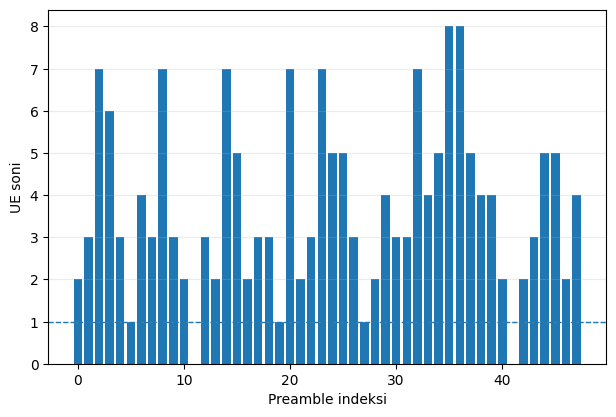

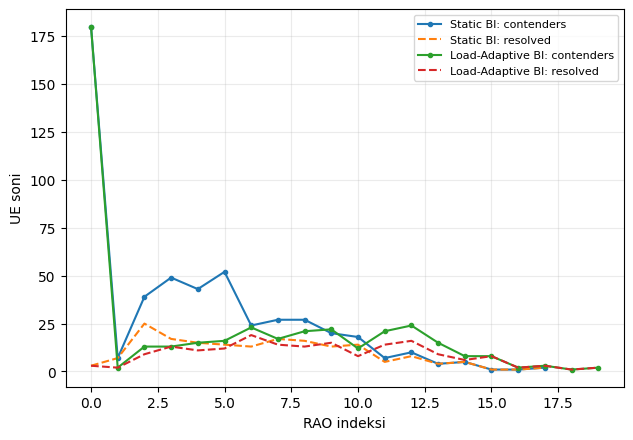

In [4]:
# First-RAO occupancy for the same seed.
rng=np.random.default_rng(v['seed'])
choices=rng.integers(0,v['n_preambles'],size=v['n_devices'])
occ=np.bincount(choices,minlength=v['n_preambles'])
plt.figure(figsize=(7.2,4.6)); plt.bar(np.arange(v['n_preambles']),occ); plt.axhline(1,linestyle='--',linewidth=1.0); plt.xlabel('Preamble indeksi'); plt.ylabel('UE soni'); plt.grid(axis='y',alpha=.25); plt.show()

plt.figure(figsize=(7.2,4.9))
for pol,o in outputs.items():
    tr=o['rao_trace']; plt.plot(tr.rao,tr.contenders,marker='o',markersize=3,label=f'{pol}: contenders'); plt.plot(tr.rao,tr.resolved_singletons,linestyle='--',label=f'{pol}: resolved')
plt.xlabel('RAO indeksi'); plt.ylabel('UE soni'); plt.legend(fontsize=8); plt.grid(alpha=.25); plt.show()

## 5. Load, preamble va BI sensitivity

,load_multiplier,policy,n_runs,resolution_rate_mean,resolution_rate_ci95,resolved_within_target_rate_mean,resolved_within_target_rate_ci95,ue_collision_tx_fraction_mean,ue_collision_tx_fraction_ci95,collision_preamble_fraction_used_mean,collision_preamble_fraction_used_ci95,idle_preamble_fraction_active_mean,idle_preamble_fraction_active_ci95,mean_attempts_per_device_mean,mean_attempts_per_device_ci95,p95_contention_wait_ms_mean,p95_contention_wait_ms_ci95,p99_contention_wait_ms_mean,p99_contention_wait_ms_ci95,calendar_preamble_efficiency_mean,calendar_preamble_efficiency_ci95
0,0.5,Static BI,10,1.00000,0.00000,1.00000,0.00000,0.53922,0.01335,0.31347,0.01277,0.76874,0.01093,2.17444,0.06245,45.325,3.00644,53.830,4.42259,0.15485,0.01253
1,0.5,Load-Adaptive BI,10,1.00000,0.00000,1.00000,0.00000,0.51319,0.01108,0.28649,0.01045,0.80792,0.01848,2.05667,0.04631,55.000,5.06070,64.885,6.59156,0.13259,0.01604
2,1.0,Static BI,10,1.00000,0.00000,1.00000,0.00000,0.65771,0.00471,0.39384,0.00515,0.63075,0.01230,2.92278,0.04050,66.025,2.44067,74.945,2.96323,0.21906,0.01004
3,1.0,Load-Adaptive BI,10,1.00000,0.00000,0.99833,0.00232,0.56847,0.01455,0.28573,0.01864,0.73085,0.01259,2.32333,0.07592,80.525,3.42490,91.025,3.76850,0.18824,0.00768
4,1.5,Static BI,10,1.00000,0.00000,0.99296,0.00425,0.73206,0.00580,0.46324,0.00825,0.53311,0.01167,3.73630,0.08146,87.775,2.96210,99.965,2.51083,0.24559,0.01038
5,1.5,Load-Adaptive BI,10,0.99963,0.00073,0.94926,0.01572,0.61156,0.01896,0.30562,0.02698,0.66851,0.01653,2.58963,0.14206,100.275,4.30559,113.125,4.91570,0.22552,0.01191
6,2.0,Static BI,10,0.97500,0.00544,0.86250,0.01434,0.79572,0.00408,0.54267,0.00698,0.42207,0.01276,4.77639,0.07718,112.425,2.31455,126.305,1.56980,0.25984,0.00802
7,2.0,Load-Adaptive BI,10,0.99917,0.00083,0.84917,0.01077,0.66558,0.00482,0.36128,0.00872,0.59882,0.01089,2.98917,0.04298,118.000,2.61333,132.530,3.65056,0.24959,0.00818


,n_preambles,policy,n_runs,resolution_rate_mean,resolution_rate_ci95,resolved_within_target_rate_mean,resolved_within_target_rate_ci95,ue_collision_tx_fraction_mean,ue_collision_tx_fraction_ci95,collision_preamble_fraction_used_mean,collision_preamble_fraction_used_ci95,idle_preamble_fraction_active_mean,idle_preamble_fraction_active_ci95,mean_attempts_per_device_mean,mean_attempts_per_device_ci95,p95_contention_wait_ms_mean,p95_contention_wait_ms_ci95,p99_contention_wait_ms_mean,p99_contention_wait_ms_ci95,calendar_preamble_efficiency_mean,calendar_preamble_efficiency_ci95
0,24,Static BI,10,0.96778,0.01375,0.83667,0.02648,0.79960,0.00828,0.55004,0.01598,0.41615,0.01415,4.84333,0.15392,113.875,2.53798,127.800,3.06789,0.26154,0.00803
1,24,Load-Adaptive BI,10,1.00000,0.00000,0.86778,0.02171,0.65214,0.00941,0.34259,0.01433,0.57471,0.01277,2.87944,0.07481,116.050,4.04909,127.235,3.26781,0.27554,0.00973
2,36,Static BI,10,1.00000,0.00000,0.99722,0.00372,0.70948,0.00949,0.43956,0.01583,0.55422,0.01199,3.45111,0.11843,79.525,4.23563,91.130,4.54272,0.24499,0.01073
3,36,Load-Adaptive BI,10,1.00000,0.00000,0.98000,0.00921,0.59429,0.01402,0.28970,0.01972,0.68642,0.01740,2.47222,0.09181,94.050,3.20799,103.920,4.16930,0.22119,0.00929
4,48,Static BI,10,1.00000,0.00000,1.00000,0.00000,0.65771,0.00471,0.39384,0.00515,0.63075,0.01230,2.92278,0.04050,66.025,2.44067,74.945,2.96323,0.21906,0.01004
5,48,Load-Adaptive BI,10,1.00000,0.00000,0.99833,0.00232,0.56847,0.01455,0.28573,0.01864,0.73085,0.01259,2.32333,0.07592,80.525,3.42490,91.025,3.76850,0.18824,0.00768
6,64,Static BI,10,1.00000,0.00000,1.00000,0.00000,0.61584,0.00770,0.36421,0.01067,0.70328,0.01302,2.60556,0.05232,56.100,3.18831,65.630,3.34957,0.18436,0.01120
7,64,Load-Adaptive BI,10,1.00000,0.00000,1.00000,0.00000,0.55209,0.01395,0.29122,0.01688,0.77172,0.01797,2.23778,0.07151,70.050,5.24745,79.025,5.76532,0.15740,0.00911


,base_bi_ms,policy,n_runs,resolution_rate_mean,resolution_rate_ci95,resolved_within_target_rate_mean,resolved_within_target_rate_ci95,ue_collision_tx_fraction_mean,ue_collision_tx_fraction_ci95,collision_preamble_fraction_used_mean,collision_preamble_fraction_used_ci95,idle_preamble_fraction_active_mean,idle_preamble_fraction_active_ci95,mean_attempts_per_device_mean,mean_attempts_per_device_ci95,p95_contention_wait_ms_mean,p95_contention_wait_ms_ci95,p99_contention_wait_ms_mean,p99_contention_wait_ms_ci95,calendar_preamble_efficiency_mean,calendar_preamble_efficiency_ci95
0,10,Static BI,10,1.0,0.0,1.00000,0.00000,0.72716,0.00653,0.47560,0.01091,0.52697,0.01981,3.67000,0.08748,61.050,1.95018,68.420,2.27404,0.24650,0.01187
1,10,Load-Adaptive BI,10,1.0,0.0,1.00000,0.00000,0.64369,0.01285,0.37547,0.01489,0.61558,0.01727,2.81500,0.10027,62.025,2.98721,68.525,3.34897,0.23988,0.01046
2,20,Static BI,10,1.0,0.0,1.00000,0.00000,0.65771,0.00471,0.39384,0.00515,0.63075,0.01230,2.92278,0.04050,66.025,2.44067,74.945,2.96323,0.21906,0.01004
3,20,Load-Adaptive BI,10,1.0,0.0,0.99833,0.00232,0.56847,0.01455,0.28573,0.01864,0.73085,0.01259,2.32333,0.07592,80.525,3.42490,91.025,3.76850,0.18824,0.00768
4,40,Static BI,10,1.0,0.0,0.98944,0.00379,0.58857,0.00705,0.30849,0.00883,0.75062,0.00692,2.43222,0.04188,81.100,3.18831,99.180,5.38775,0.16105,0.00726
5,40,Load-Adaptive BI,10,1.0,0.0,0.72167,0.05903,0.52601,0.00789,0.23241,0.01028,0.84299,0.00805,2.11111,0.03500,132.125,8.53852,149.075,8.32085,0.11264,0.00431
6,80,Static BI,10,1.0,0.0,0.90111,0.02423,0.54523,0.00928,0.25666,0.01201,0.83142,0.00390,2.20111,0.04553,123.175,7.60441,148.680,5.21486,0.11153,0.00635
7,80,Load-Adaptive BI,10,1.0,0.0,0.37778,0.02949,0.51093,0.00394,0.21352,0.00606,0.90992,0.00477,2.04500,0.01643,251.100,17.90512,274.940,19.87990,0.06312,0.00421
8,160,Static BI,10,1.0,0.0,0.55778,0.01704,0.51671,0.00362,0.22102,0.00564,0.88517,0.00448,2.06944,0.01551,185.200,15.98045,258.890,22.72323,0.06381,0.00460
9,160,Load-Adaptive BI,10,1.0,0.0,0.19833,0.02190,0.50311,0.00382,0.20380,0.00561,0.94743,0.00399,2.01278,0.01549,551.300,115.16163,580.095,119.12489,0.03220,0.00459


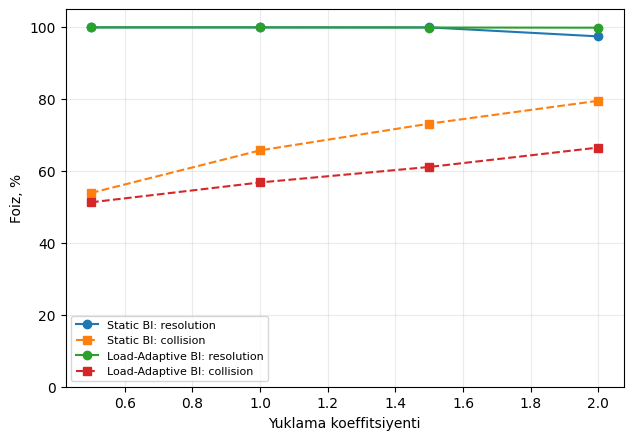

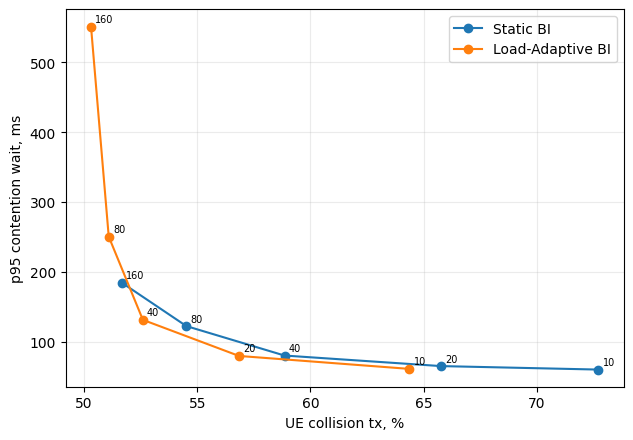

In [5]:
load_df=load_sweep_mc(v,(0.5,1.0,1.5,2.0),n_runs=10,seed_offsets=tuple(range(10)))
preamble_df=preamble_sensitivity_mc(v,(24,36,48,64),n_runs=10,seed_offsets=tuple(range(10)))
bi_df=bi_sensitivity_mc(v,(10,20,40,80,160),n_runs=10,seed_offsets=tuple(range(10)))
display(load_df.round(5)); display(preamble_df.round(5)); display(bi_df.round(5))

plt.figure(figsize=(7.2,4.9))
for pol in POLICIES:
    g=load_df[load_df.policy==pol].sort_values('load_multiplier')
    plt.plot(g.load_multiplier,100*g.resolution_rate_mean,marker='o',label=f'{pol}: resolution')
    plt.plot(g.load_multiplier,100*g.ue_collision_tx_fraction_mean,marker='s',linestyle='--',label=f'{pol}: collision')
plt.xlabel('Yuklama koeffitsiyenti'); plt.ylabel('Foiz, %'); plt.ylim(0,105); plt.legend(fontsize=8); plt.grid(alpha=.25); plt.show()

plt.figure(figsize=(7.2,4.9))
for pol in POLICIES:
    g=bi_df[bi_df.policy==pol].sort_values('base_bi_ms')
    plt.plot(100*g.ue_collision_tx_fraction_mean,g.p95_contention_wait_ms_mean,marker='o',label=pol)
    for _,r in g.iterrows(): plt.annotate(str(int(r.base_bi_ms)),(100*r.ue_collision_tx_fraction_mean,r.p95_contention_wait_ms_mean),textcoords='offset points',xytext=(3,3),fontsize=7)
plt.xlabel('UE collision tx, %'); plt.ylabel('p95 contention wait, ms'); plt.legend(); plt.grid(alpha=.25); plt.show()

## 6. CSV saqlash va sanity-checklar

In [6]:
prefix=f'A7v2_variant_{VARIANT:02d}'
pd.DataFrame([th]).to_csv(prefix+'_first_rao_theory.csv',index=False)
comparison_df.to_csv(prefix+'_single_run_kpi.csv',index=False)
mc_summary.to_csv(prefix+'_mc_summary.csv',index=False)
mc_raw.to_csv(prefix+'_mc_raw.csv',index=False)
load_df.to_csv(prefix+'_load_sweep_mc.csv',index=False)
preamble_df.to_csv(prefix+'_preamble_sensitivity_mc.csv',index=False)
bi_df.to_csv(prefix+'_bi_sensitivity_mc.csv',index=False)
for pol,o in outputs.items():
    suffix='static' if pol=='Static BI' else 'adaptive'
    o['rao_trace'].to_csv(prefix+f'_rao_trace_{suffix}.csv',index=False)
for pol,o in outputs.items():
    k=o['kpi']
    assert k['resolved_devices']+k['failed_devices']==v['n_devices']
    assert 0<=k['resolution_rate']<=1 and 0<=k['resolved_within_target_rate']<=k['resolution_rate']+1e-12
    assert 0<=k['ue_collision_tx_fraction']<=1 and 0<=k['collision_preamble_fraction_used']<=1
assert set(mc_summary.policy)==set(POLICIES)
print('OK')

OK


## 7. Talaba xulosasi
6–8 gapda $G=N/M$, idle/singleton/collision occupancy, Static BI va Load-Adaptive BI trade-offi, failure-aware $P_{resolve@T}$, Monte Carlo 95% CI hamda load/preamble/BI sensitivity natijalarini izohlang.